<a href="https://colab.research.google.com/github/bhadrasuresh80-code/Hotel-booking-revenue-customer-analysis/blob/main/Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# HOTEL BOOKING, REVENUE & CUSTOMER BEHAVIOUR ANALYSIS

## 1. Project Overview

This project focuses on analysing hotel booking data to understand booking patterns, revenue performance, customer behaviour and cancellation trends.

The analysis aims to identify meaningful business insights that can help hotel management improve revenue performance, understand customer preferences and make better business decisions.

## 2. Project Objectives

- Analyse hotel booking trends and seasonal patterns.
- Evaluate hotel revenue performance.
- Identify factors influencing booking cancellations.
- Understand customer demographics and booking behaviour.
- Analyse customer types and repeat guest patterns.
- Identify high-performing hotel types and market segments.
- Generate actionable business recommendations.

## 3. Dataset Description

**Dataset Name:** Hotel Booking Demand

**Source:** Kaggle

**Total Records:** 119,390

**Total Columns:** 32

**Hotel Types:** City Hotel and Resort Hotel

**Time Period:** 2015 – 2017

## 4. Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- MySQL
- Power BI

## 5. Project Workflow

1. Data Loading and Understanding
2. Data Quality Assessment
3. Data Cleaning and Preprocessing
4. Feature Engineering
5. Exploratory Data Analysis (EDA)
6. SQL Business Analysis
7. Interactive Power BI Dashboard
8. Business Insights and Recommendations



In [ ]:
import pandas as pd
import numpy as np
df = pd.read_csv("/content/hotel_bookings.csv")

In [ ]:
print("=== 1. INITIAL INSPECTION ===")
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print(df.info())

print("\n=== 2. STATISTICAL SUMMARY ===")
display(df.describe())

print("\n=== 3. CHECKING DUPLICATES ===")
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows found: {duplicate_count} ({round(duplicate_count / len(df) * 100, 2)}%)")

print("\n=== 4. CHECKING MISSING VALUES ===")
missing_values = df.isnull().sum()
missing_df = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing Percentage (%)': (missing_values / len(df)) * 100
})
display(missing_df[missing_df['Missing Count'] > 0])


# ==========================================
# 5. DATA CLEANING & HANDLING
# ==========================================
print("\n=== 5. EXECUTING DATA CLEANING ===")

# A. Handle Missing Values
# children: fill missing with 0 (no children)
df['children'] = df['children'].fillna(0)
# country: fill missing with 'Unknown'
df['country'] = df['country'].fillna('Unknown')
# agent & company: fill missing with 0 (no agent/corporate company involved)
df['agent'] = df['agent'].fillna(0)
df['company'] = df['company'].fillna(0)

# B. Handle Duplicates
# Drop duplicate rows to prevent skewed analysis
df = df.drop_duplicates()
print(f"Shape after removing duplicates: {df.shape}")

# C. Feature Engineering for Business Analysis
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['total_stay_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_revenue'] = df['total_stay_nights'] * df['adr']

# D. Clean Outliers (e.g., negative ADR)
df = df[df['adr'] >= 0]

# Save the cleaned dataset for SQL and Power BI
df.to_csv('cleaned_hotel_bookings.csv', index=False)
print("\nData cleaning complete! Cleaned dataset saved as 'cleaned_hotel_bookings.csv'.")

=== 1. INITIAL INSPECTION ===
Dataset Shape: 119390 rows, 32 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies  

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000



=== 3. CHECKING DUPLICATES ===
Number of duplicate rows found: 31994 (26.8%)

=== 4. CHECKING MISSING VALUES ===


,Missing Count,Missing Percentage (%)
children,4,0.003350
country,488,0.408744
agent,16340,13.686238
company,112593,94.306893



=== 5. EXECUTING DATA CLEANING ===
Shape after removing duplicates: (87396, 32)

Data cleaning complete! Cleaned dataset saved as 'cleaned_hotel_bookings.csv'.


Loaded Cleaned Dataset Shape: (87395, 35)

=== BASIC STATISTICAL METRICS (CLEANED) ===
Overall Cancellation Rate: 27.49%
Average Lead Time: 79.89 days
Average Daily Rate (ADR): $106.34

--- Bookings by Hotel Type ---
hotel
City Hotel      61.133932
Resort Hotel    38.866068
Name: proportion, dtype: float64

--- Average ADR by Hotel Type ---
hotel
City Hotel      110.985944
Resort Hotel     99.028449
Name: adr, dtype: float64


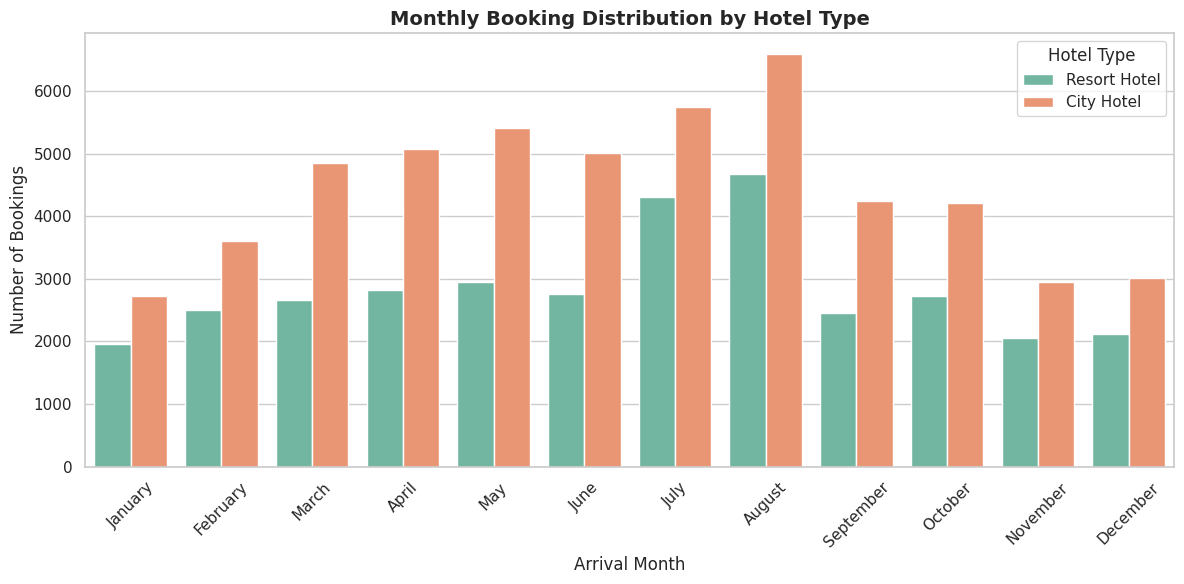

/tmp/ipykernel_2659/3356422490.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_canc, x='market_segment', y='cancellation_rate_pct', palette='coolwarm')


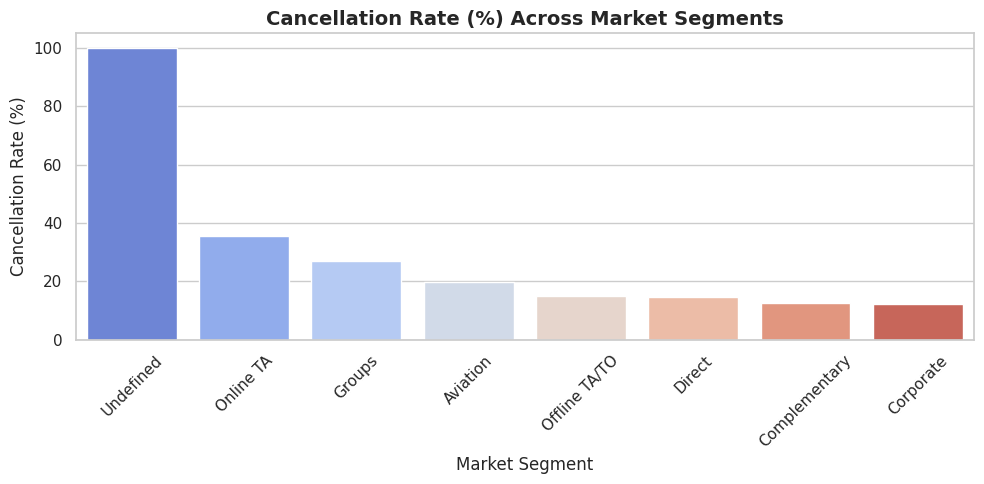

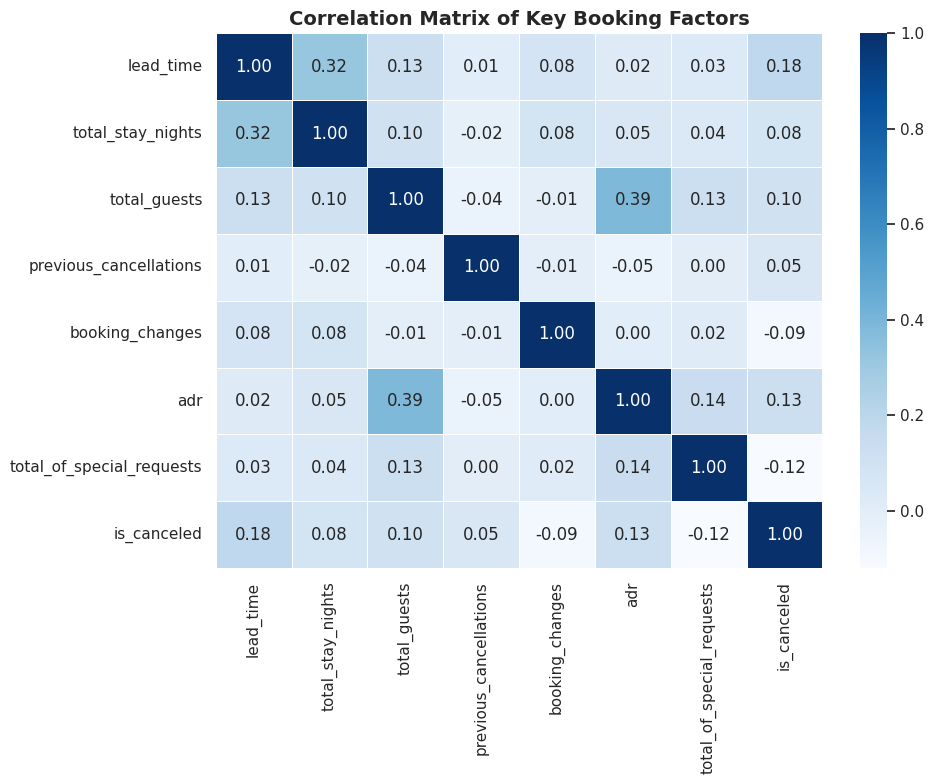

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set publication-grade styling
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Load the Cleaned Dataset
df = pd.read_csv('cleaned_hotel_bookings.csv')
print(f"Loaded Cleaned Dataset Shape: {df.shape}\n")

# ==========================================
# 2. EXPLORATORY DATA ANALYSIS (Numerical Stats)
# ==========================================
print("=== BASIC STATISTICAL METRICS (CLEANED) ===")
print(f"Overall Cancellation Rate: {round(df['is_canceled'].mean() * 100, 2)}%")
print(f"Average Lead Time: {round(df['lead_time'].mean(), 2)} days")
print(f"Average Daily Rate (ADR): ${round(df['adr'].mean(), 2)}")

print("\n--- Bookings by Hotel Type ---")
print(df['hotel'].value_counts(normalize=True) * 100)

print("\n--- Average ADR by Hotel Type ---")
print(df.groupby('hotel')['adr'].mean())


# ==========================================
# 3. MATPLOTLIB / SEABORN VISUALIZATIONS
# ==========================================

# Chart 1: Monthly Booking Distribution by Hotel Type
plt.figure(figsize=(12, 6))
order_months = ['January', 'February', 'March', 'April', 'May', 'June',
                'July', 'August', 'September', 'October', 'November', 'December']
sns.countplot(data=df, x='arrival_date_month', hue='hotel', order=order_months, palette='Set2')
plt.title('Monthly Booking Distribution by Hotel Type', fontsize=14, fontweight='bold')
plt.xlabel('Arrival Month', fontsize=12)
plt.ylabel('Number of Bookings', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Hotel Type')
plt.tight_layout()
plt.show()

# Chart 2: Cancellation Rate by Market Segment
plt.figure(figsize=(10, 5))
segment_canc = df.groupby('market_segment')['is_canceled'].mean().reset_index()
segment_canc['cancellation_rate_pct'] = segment_canc['is_canceled'] * 100
segment_canc = segment_canc.sort_values(by='cancellation_rate_pct', ascending=False)

sns.barplot(data=segment_canc, x='market_segment', y='cancellation_rate_pct', palette='coolwarm')
plt.title('Cancellation Rate (%) Across Market Segments', fontsize=14, fontweight='bold')
plt.xlabel('Market Segment', fontsize=12)
plt.ylabel('Cancellation Rate (%)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Chart 3: Correlation Heatmap of Numerical Features
plt.figure(figsize=(10, 8))
numeric_cols = ['lead_time', 'total_stay_nights', 'total_guests',
                'previous_cancellations', 'booking_changes', 'adr',
                'total_of_special_requests', 'is_canceled']

corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5, cbar=True)
plt.title('Correlation Matrix of Key Booking Factors', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
import sqlite3
import pandas as pd

# Load the cleaned dataset
df = pd.read_csv('cleaned_hotel_bookings.csv')

# Connect to SQLite database (this creates hotel_bookings.db in your environment)
conn = sqlite3.connect('hotel_bookings.db')

# Write the dataframe into an SQL table named 'hotel_bookings'
df.to_sql('hotel_bookings', conn, if_exists='replace', index=False)

print("Database 'hotel_bookings.db' created and table 'hotel_bookings' populated successfully!")
conn.close()

Database 'hotel_bookings.db' created and table 'hotel_bookings' populated successfully!


In [ ]:
import sqlite3
import pandas as pd

# Connect to your SQLite database
conn = sqlite3.connect('hotel_bookings.db')

# 1. Monthly Revenue and Successful Bookings Trend
query_monthly = """
SELECT
    arrival_date_year,
    arrival_date_month,
    hotel,
    COUNT(*) AS total_bookings,
    SUM(CASE WHEN is_canceled = 0 THEN 1 ELSE 0 END) AS successful_bookings,
    ROUND(AVG(adr), 2) AS avg_adr,
    ROUND(SUM(CASE WHEN is_canceled = 0 THEN total_revenue ELSE 0 END), 2) AS total_realized_revenue
FROM hotel_bookings
GROUP BY arrival_date_year, arrival_date_month, hotel
ORDER BY arrival_date_year, arrival_date_month;
"""

df_monthly = pd.read_sql(query_monthly, conn)
print("=== Monthly Revenue & Bookings ===")
display(df_monthly.head(10))

# 2. Cancellation Rate by Market Segment
query_segment = """
SELECT
    market_segment,
    COUNT(*) AS total_bookings,
    SUM(is_canceled) AS canceled_bookings,
    ROUND((SUM(is_canceled) * 100.0) / COUNT(*), 2) AS cancellation_rate_pct,
    ROUND(SUM(CASE WHEN is_canceled = 1 THEN total_revenue ELSE 0 END), 2) AS estimated_lost_revenue
FROM hotel_bookings
GROUP BY market_segment
ORDER BY cancellation_rate_pct DESC;
"""

df_segment = pd.read_sql(query_segment, conn)
print("\n=== Cancellation Rate by Market Segment ===")
display(df_segment)

conn.close()

=== Monthly Revenue & Bookings ===


,arrival_date_year,arrival_date_month,hotel,total_bookings,successful_bookings,avg_adr,total_realized_revenue
0,2015,August,City Hotel,1107,878,82.98,214566.27
1,2015,August,Resort Hotel,1346,1004,155.90,827013.51
2,2015,December,City Hotel,1020,800,82.67,187436.54
3,2015,December,Resort Hotel,962,810,59.74,153771.20
4,2015,July,City Hotel,395,163,66.81,29450.71
5,2015,July,Resort Hotel,1279,999,126.48,644005.28
6,2015,November,City Hotel,797,660,73.90,141474.88
7,2015,November,Resort Hotel,868,762,45.77,125515.89
8,2015,October,City Hotel,1559,1270,95.09,349082.95
9,2015,October,Resort Hotel,1141,990,56.84,226824.92



=== Cancellation Rate by Market Segment ===


,market_segment,total_bookings,canceled_bookings,cancellation_rate_pct,estimated_lost_revenue
0,Undefined,2,2,100.00,48.00
1,Online TA,51618,18245,35.35,9292901.94
2,Groups,4941,1335,27.02,315619.75
3,Aviation,227,45,19.82,14065.00
4,Offline TA/TO,13889,2063,14.85,821008.82
5,Direct,11804,1737,14.72,929714.23
6,Complementary,702,88,12.54,269.99
7,Corporate,4212,510,12.11,110415.25


In [ ]:
import os
import pandas as pd

print("Current file location:")
print(os.path.abspath('/content/cleaned_hotel_bookings.csv'))

print("\nCurrent cleaned dataset:")
cleaned = pd.read_csv('/content/cleaned_hotel_bookings.csv')
print(cleaned.shape)

print("\nHotel distribution:")
print(cleaned['hotel'].value_counts())

print("\nYear distribution:")
print(cleaned['arrival_date_year'].value_counts())

print("\nCancellation rate:")
print(cleaned['is_canceled'].mean() * 100)

Current file location:
/content/cleaned_hotel_bookings.csv

Current cleaned dataset:
(87395, 35)

Hotel distribution:
hotel
City Hotel      53428
Resort Hotel    33967
Name: count, dtype: int64

Year distribution:
arrival_date_year
2016    42391
2017    31691
2015    13313
Name: count, dtype: int64

Cancellation rate:
27.49013101436009


In [ ]:
import pandas as pd

# Load the correct cleaned dataset
df = pd.read_csv('/content/cleaned_hotel_bookings.csv')

# Convert month names into month numbers
month_map = {
    'January': 1, 'February': 2, 'March': 3,
    'April': 4, 'May': 5, 'June': 6,
    'July': 7, 'August': 8, 'September': 9,
    'October': 10, 'November': 11, 'December': 12
}

# Create arrival date
df['arrival_date'] = pd.to_datetime({
    'year': df['arrival_date_year'],
    'month': df['arrival_date_month'].map(month_map),
    'day': df['arrival_date_day_of_month']
}, errors='coerce')

# Create realized room revenue estimate
df['realized_revenue'] = df['total_revenue'].where(
    df['is_canceled'] == 0, 0
)

# Save final dataset
df.to_csv('/content/Final_Hotel_Booking_Dataset.csv', index=False)

print("Final Dataset Shape:", df.shape)
print("Missing Arrival Dates:", df['arrival_date'].isna().sum())
print("Final dataset exported successfully!")

Final Dataset Shape: (87395, 37)
Missing Arrival Dates: 0
Final dataset exported successfully!


In [ ]:
# Ensure you are saving the full cleaned dataframe
df.to_csv('Final_Hotel_Booking_Dataset.csv', index=False)
print("Total rows exported:", len(df))  # Should output 87395

Total rows exported: 87395


In [ ]:
df.to_csv('Final_Hotel_Booking_Dataset.csv', index=False)
print("Verified rows:", len(df))

Verified rows: 87395
